<a href="https://colab.research.google.com/github/Marc0s-ikp/imperial_eee_machine_learning_course-main/blob/master/03_ML_NLFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Non-linear Feature Transformation


---


A linear model calculates its output from a weighted combination of the input features (known as signal):

$$
\mathbf{w}^\intercal \mathbf{x} = \sum_{i=0}^{d} w_i x_i
$$

During training, the input values $\mathbf{x}$ are fixed and the learning algorithm adjusts the weights $\mathbf{w}$. For this reason, what matters to the learning algorithm is that the model remains linear with respect to its weights. The input features themselves, however, do not have to remain unchanged. We can first apply a non-linear transformation to the input and then use the transformed features with the same linear learning algorithms. We denote this transformation by: $$ \mathbf{z} = \Phi(\mathbf{x}) $$ where $\Phi$ maps the original input from the feature space $\mathcal{X}$ to a new feature space $\mathcal{Z}$. This idea can be used for both classification and regression, as we will see in the following examples.



# Classification


As not all data are linearly seperable, in fact the majority of real world problem are concerned with non-linearly seperable data. This trick is used to utilise linear models while still having non-linearly seperable data by transforming the features such that the newly transformed features are linearly seperable. This newly transformed data set—which is now linearly separable—is used as the new data set. For that purpose we can define the $\mathcal Z$-space which is the space that the transformed data belong to. Non-linear transformations can be used to transform data such that it becomes linearly separable given original data $\mathrm {x}_n \in \mathcal X$, we transform the data using $\mathrm {z}_i = \Phi (\mathrm {x}_i) \in \mathcal Z$, then separate data in the $\mathcal Z$ $\tilde {g} (\mathrm {z}) = \text {sign} (\tilde {w}^{\mathrm {T}} \mathrm {z})$, and finally classify in $\mathcal X$ such that $g(\mathrm {x}) = \tilde {g} (\Phi (\mathrm {x})) = \text {sign} (\tilde {w}^{\mathrm {T}} \Phi (\mathrm {x}))$. This process is summarised below:


$$
\begin{align}
\mathrm {x} = (x_0, x_1, \dots, x_d)\ &\xrightarrow{\Phi}\ \mathrm {z} = (z_0, z_1, \dots \dots, z_{\tilde d}) \\
\mathrm { x_1, x_2, \dots, x_n}\      &\xrightarrow{\Phi}\ \mathrm {z_1, z_2, \dots, z_n } \\
\mathrm { y_1, y_2, \dots, y_n}\      &\xrightarrow{\Phi}\ \mathrm {y_1, y_2, \dots, y_n } \\
\text {no weights in}\ \mathcal {X}\  &\phantom {\xrightarrow{\Phi}\ } \mathrm {\tilde {w}} = (w_0, w_1, \dots \dots, w_{\tilde {d}}) \\
g(\mathrm {x}) = \text {sign} (\mathrm {\tilde {w}^T z}) &= \text {sign} (\mathrm {\tilde {w}^T \Phi (x)})
\end{align}
$$


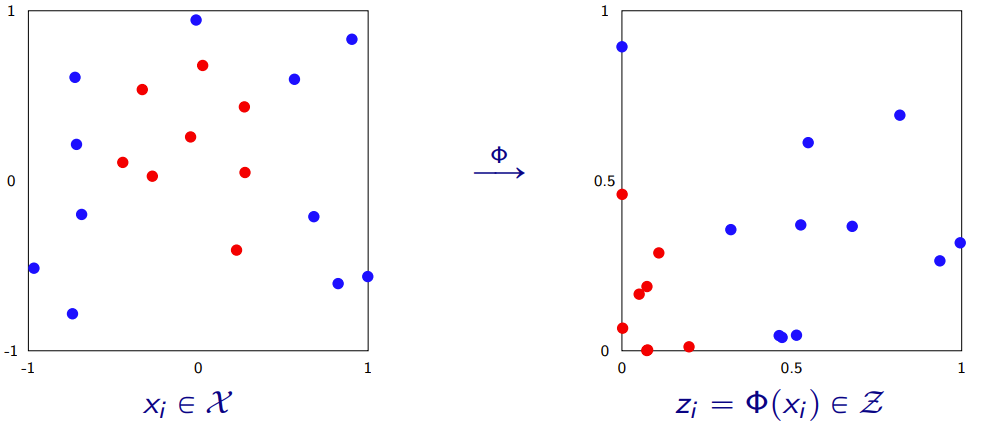

In the upcoming code cell, a piece of code is given that will generate a dummy non-linearly separable data for us. We will then use the Perceptron Learning Algorithm (PLA) that we learned about in the first exercise to classify this newly generated data. To make things more convenient for you, the code for the PLA is provided right below.

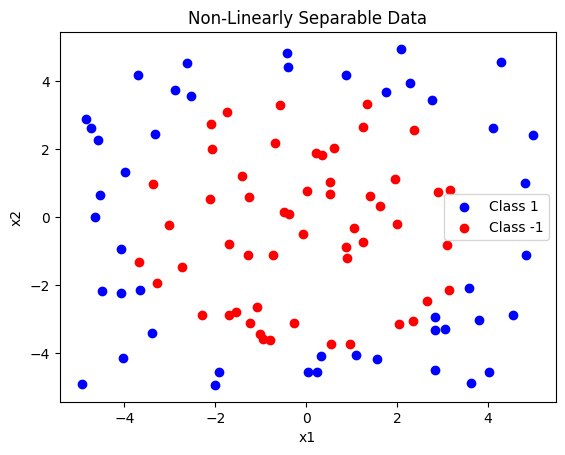

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def generate_non_linearly_separable_data(num_samples, random_seed=32):
    # Set the random seed for consistent data generation
    np.random.seed(random_seed)
    # Generate random data points for x1 and x2 in the range [-5, 5]
    x1 = np.random.uniform(-5, 5, num_samples)
    x2 = np.random.uniform(-5, 5, num_samples)

    # Assign labels such that the data points are not linearly separable
    labels = np.where(x1**2 + x2**2 >= 16, 1, -1)

    return x1, x2, labels

def plot_data(x1, x2, labels, title):
    # Plot the data points with different colors for each class
    plt.scatter(x1[labels==1], x2[labels==1], c='b', marker='o', label='Class 1')
    plt.scatter(x1[labels==-1], x2[labels==-1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title(title)
    plt.show()

num_samples_per_class = 50  # Half of the samples for each class
x1, x2, labels = generate_non_linearly_separable_data(num_samples_per_class * 2)

# Stack the data in one numpy array to distinguish them from the tranformed data later on

X_original = np.column_stack((x1, x2))

# Plot non-linearly separable data
plot_data(x1, x2, labels, 'Non-Linearly Separable Data')

In [2]:
# PLA code below

def predict(W, X):
        """ Return class label after each setp """
        return np.where(net_input(W, X) >= 0.0, 1, -1)

def net_input(W, X):
        """ Calculate net input """
        return np.dot(X, W[1:]) + W[0]

def plot_boundary(W, X, y):
    """Function to plot the boundary defined by the weights. Given equation."""
    """w0 + w1*x1 + w2*x2 = 0, used to generate the line."""

    # Calculate the slope and y-intercept of the boundary line
    slope = -W[1] / W[2]
    intercept = -W[0] / W[2]

    # Get the minimum and maximum x values from the dataset
    x_min = np.min(X[:, 0])
    x_max = np.max(X[:, 0])

    # Generate points for the boundary line to cover the whole plot
    x_vals = np.array([x_min, x_max])
    y_vals = slope * x_vals + intercept

    # This part here define the x-axis and y-axis style according to the data we are using
    plt.scatter(X[y==1, 0], X[y==1, 1], c='b', marker='o', label='Class 1')
    plt.scatter(X[y==-1, 0], X[y==-1, 1], c='r', marker='o', label='Class -1')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.title('title')

    # Plot the line using the calculated points
    plt.plot(x_vals, y_vals, 'black')

    plt.show()

def plot_errors(error):
    plt.plot(range(1, len(error) + 1), error,marker='o')
    plt.xlabel('Iterations')
    plt.ylabel('Number of misclassifications')
    # Set the x-axis ticks to display only integer values
    # Set the x-axis ticks to be automatically determined based on available space
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

def pla(n_iter, X, y):
        W = np.zeros(1 + X.shape[1])
        errors_ = []
        for i in range(n_iter):
            for j, (xi, target) in enumerate(zip(X,y)):
         #     update = target - predict(W, xi)
         #     W += 0.5*update*np.append(1,xi)
              if predict(W, xi) != target:
                  W = W + target * np.append(1,xi)
            # errors on whole dataset
            errors = 0
            for j, (xi, target) in enumerate(zip(X, y)):
                if predict(W, xi) != target:
                    errors += 1
            # -------------------------------------------
            errors_.append(errors)
            i += 1
            print ("Iteration: ", i)
            print("Weights: ", W)
            print("Misclassified Samples: ", errors)
            plot_boundary(W,X,y)  #When weights are updated we plot the boundary

        plot_errors(errors_)

## Task 1 [40 marks]

1. Write a function to transform the provided data while retaining its original feature space dimensions. The objective is to get linearly separable data through this transformation. The resulting transformed data, represented as `x1_transformed` and `x2_transformed` can then be merged into a single NumPy array, serving as input for the pla function as we did with the original data.

2. Generate a plot that visually demonstrates the linear separability achieved by the transformed data. Execute the Perceptron Learning Algorithm (`pla`) using this transformed data. Present the following outcomes:
  - Final classifier weights.
  - Visualisation of the decision boundary.
  - Display of correctly classified samples.
  - Identification of the iteration at which the PLA achieved perfect classification.

3. Create a plot of the original labeled data and overlay the deicision boundary expressed in the original coordinates.

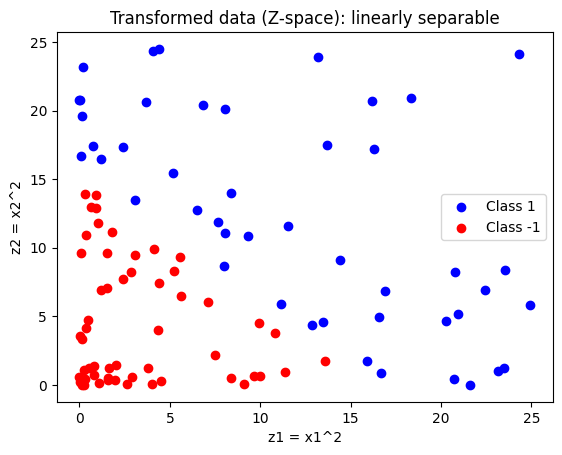

In [3]:
# Task 1
def transform(x1, x2):
    x1_transformed = x1 ** 2
    x2_transformed = x2 ** 2
    return x1_transformed, x2_transformed

x1_transformed, x2_transformed = transform(x1, x2)
X_transformed = np.column_stack((x1_transformed, x2_transformed))

# Plot of the transformed data — now linearly separable
plt.scatter(x1_transformed[labels == 1], x2_transformed[labels == 1], c='b', label='Class 1')
plt.scatter(x1_transformed[labels == -1], x2_transformed[labels == -1], c='r', label='Class -1')
plt.xlabel('z1 = x1^2')
plt.ylabel('z2 = x2^2')
plt.title('Transformed data (Z-space): linearly separable')
plt.legend()
plt.show()

Iteration 1: weights = [-17.           9.68524052   8.43610346], misclassified = 45
Iteration 2: weights = [-31.           1.75299895  16.10454318], misclassified = 30
Iteration 3: weights = [-42.           2.75332963  19.90039811], misclassified = 30
Iteration 4: weights = [-53.           4.56980444  11.74446629], misclassified = 27
Iteration 5: weights = [-64.           9.66400388  20.14670934], misclassified = 34
Iteration 6: weights = [-75.          -0.72575143  11.58179779], misclassified = 33
Iteration 7: weights = [-83.          12.91339811  14.07118694], misclassified = 30
Iteration 8: weights = [-93.           6.49194458  18.98925636], misclassified = 24
Iteration 9: weights = [-102.            2.90826368   12.67661856], misclassified = 24
Iteration 10: weights = [-106.            1.82917854   11.72373476], misclassified = 25
Iteration 11: weights = [-111.            3.24085336    9.18260464], misclassified = 17
Iteration 12: weights = [-114.            1.9359373    11.7204152

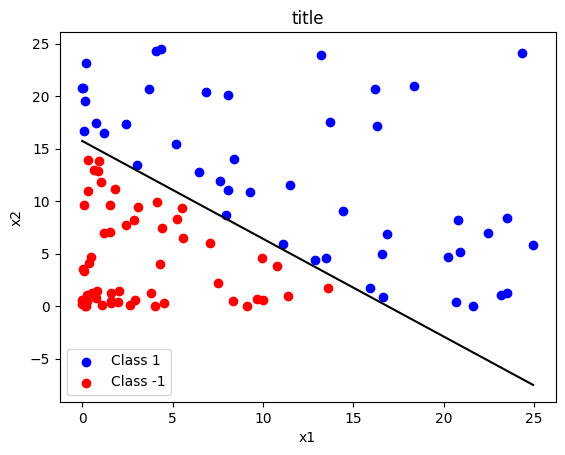

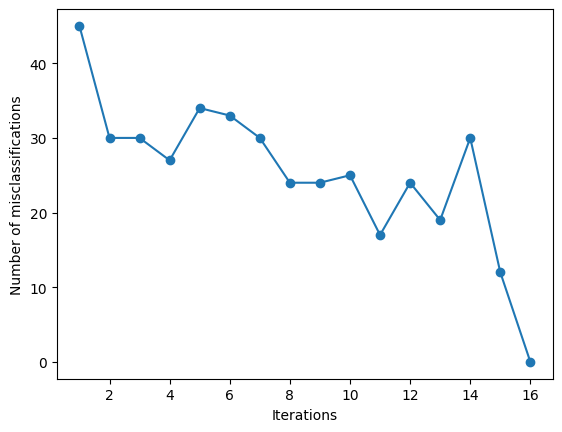

In [4]:
# Task 1 (continued)
def pla_fit(n_iter, X, y):
    W = np.zeros(1 + X.shape[1])
    errors_ = []
    for i in range(n_iter):
        for xi, target in zip(X, y):
            if predict(W, xi) != target:
                W = W + target * np.append(1, xi)
        errors = int(np.sum(predict(W, X) != y))   # misclassifications on the whole dataset
        errors_.append(errors)
        print(f"Iteration {i + 1}: weights = {W}, misclassified = {errors}")
        if errors == 0:
            break
    return W, errors_

W_z, errors_z = pla_fit(100, X_transformed, labels)
perfect_iter = errors_z.index(0) + 1

y_hat = predict(W_z, X_transformed)
print(f"\nFinal weights: w0 = {W_z[0]}, w1 = {W_z[1]}, w2 = {W_z[2]}")
print(f"Correctly classified samples: {np.sum(y_hat == labels)} / {len(labels)}")
print(f"PLA reached perfect classification at iteration {perfect_iter}")

# Decision boundary in Z-space
plot_boundary(W_z, X_transformed, labels)
plot_errors(errors_z)

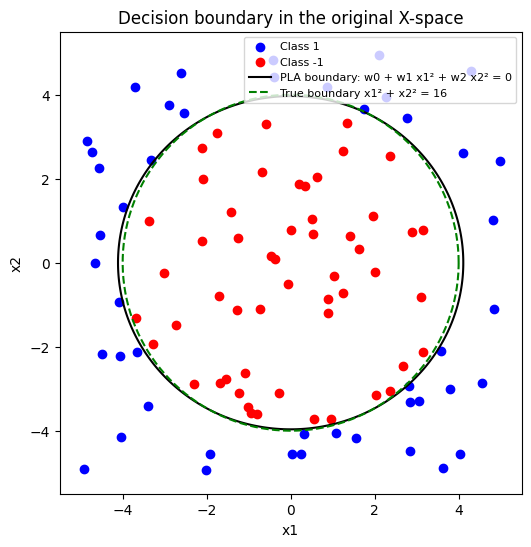

In [5]:
# Task 1 (continued)
xx1, xx2 = np.meshgrid(np.linspace(-5.5, 5.5, 400), np.linspace(-5.5, 5.5, 400))
F = W_z[0] + W_z[1] * xx1**2 + W_z[2] * xx2**2

plt.figure(figsize=(6, 6))
plt.scatter(x1[labels == 1], x2[labels == 1], c='b', label='Class 1')
plt.scatter(x1[labels == -1], x2[labels == -1], c='r', label='Class -1')
cs = plt.contour(xx1, xx2, F, levels=[0], colors='black')
plt.plot([], [], 'k', label='PLA boundary: w0 + w1 x1² + w2 x2² = 0')
theta = np.linspace(0, 2 * np.pi, 300)
plt.plot(4 * np.cos(theta), 4 * np.sin(theta), 'g--', label='True boundary x1² + x2² = 16')
plt.gca().set_aspect('equal')
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Decision boundary in the original X-space')
plt.legend(loc='upper right', fontsize=8)
plt.show()


# Regression



The same idea can also be applied to regression. A standard linear regression model represents the target as a linear combination of its input features. This works well when a straight line, plane, or hyperplane gives a reasonable description of the relationship between the inputs and the target. Some datasets, however, follow curved or more complicated patterns. Instead of changing the regression algorithm itself, we can transform the original features and fit a linear model using the transformed ones. A common example is a **polynomial transformation**. For a single feature $x_1$, a quadratic transformation can create the features: $$ 1,\ x_1,\ x_1^2 $$ The model can then take the form: $$ \hat{y} = w_0 + w_1x_1 + w_2x_1^2 $$ Although this produces a curved relationship with respect to $x_1$, the model is still linear in the weights $w_0$, $w_1$, and $w_2$. For two input features, $\mathbf{x} = (1, x_1, x_2)$, a degree-2 polynomial transformation can be written as: $$ \mathbf{x} = (1, x_1, x_2) \;\xrightarrow{\Phi}\; \mathbf{z} = (1, x_1, x_2, x_1x_2, x_1^2, x_2^2) $$ The transformed features can then be passed to a linear regression model in exactly the same way as the original features. Increasing the polynomial degree gives the model more flexibility to follow non-linear patterns in the data. The figure below shows this effect for a single input feature. The top-left plot corresponds to a standard linear fit of degree 1, while the remaining plots use higher-degree polynomial features.



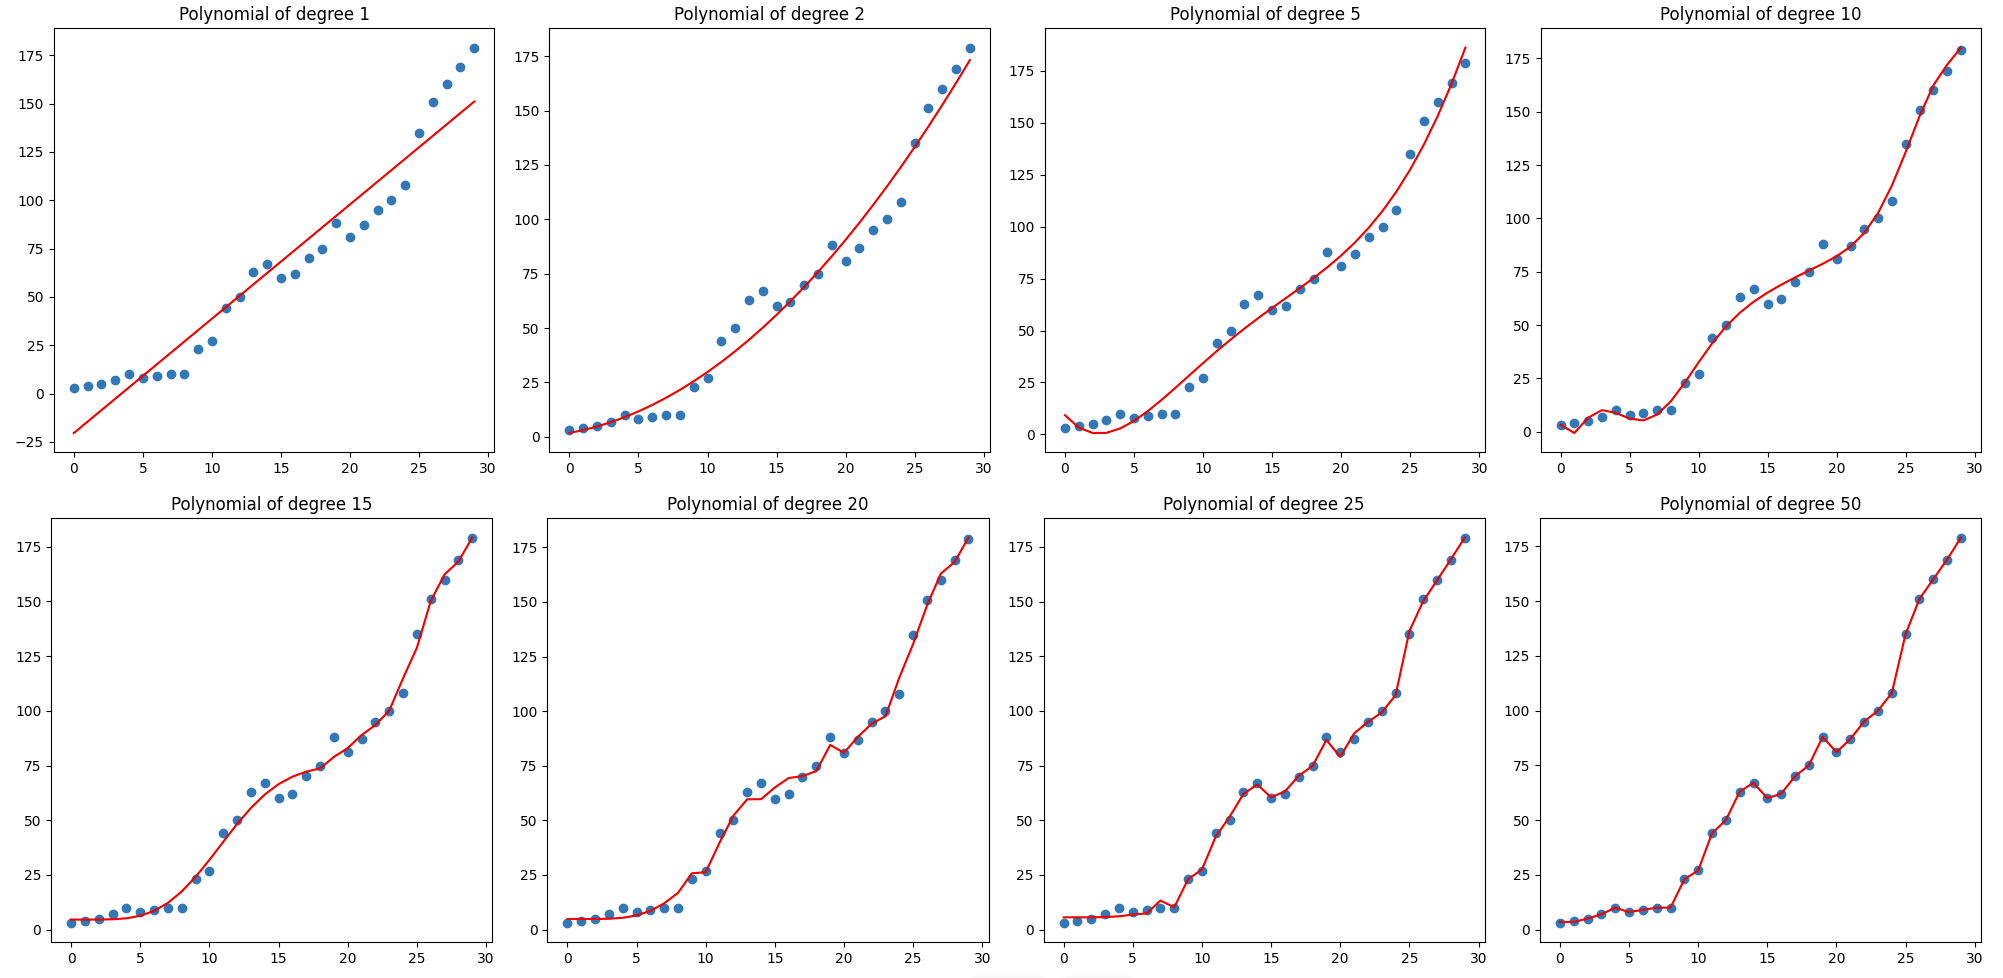

In the upcoming code cell, a piece of code is given that will generate a dummy data for regression.


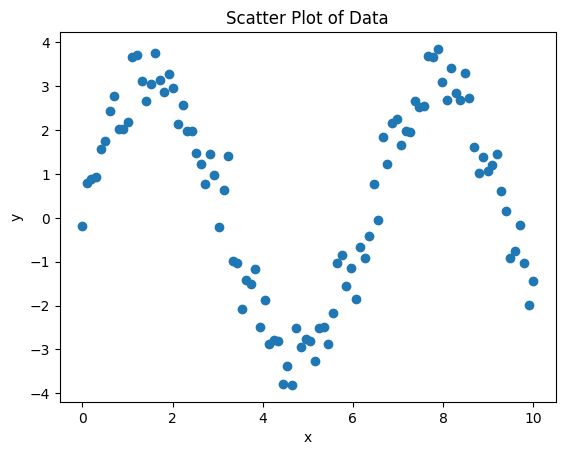

In [6]:
np.random.seed(32)  # Set a seed for reproducibility

# Generate data points with a sine-like pattern and noise
x = np.linspace(0, 10, 100)
y = 3 * np.sin(x) + np.random.normal(0, 0.5, 100)

# Plot the data
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter Plot of Data')
plt.show()

## Task 2 [60 marks]

You are required to create a function(s) that takes a single-variable input `x` and generates a polynomial transformation of a specified degree `d`. The function should provide the option to include a bias term or not, controlled by the logical parameter `include_bias`. You will then use the tranformed data to train linear regression model and get the MSE for each case.

**1. Function Description:**

- Accepts the input variable `x`.
- Accepts the polynomial degree `d`.
- Accepts the logical parameter `include_bias` (either `True` or `False`).
- Generates a polynomial transformation of degree `d` based on the value of `include_bias`. If `include_bias` is `True`, the transformation includes the bias term `1` as the first component. Otherwise, the transformation starts directly from `x^1`.
- Returns the polynomial transformation as a vector `z`.
-For instance, if you choose `d=5` and `include_bias=True`, the generated output will be `z = [1, x, x^2, x^3, x^4, x^5]`. On the other hand, if `include_bias=False`, the generated output will be `z = [x, x^2, x^3, x^4, x^5]`.

**3. Training Linear Regression Model:**
  - Use the provided degrees `[1, 3, 5, 7, 9, 11, 13, 15]`.
  - For each degree in the list, apply the polynomial transformation to the input data `x`.
  - Train a linear regression model using the transformed data and the original `y` data.
  - Visualise the results in a fixed **2×4 subplot layout**, where each subplot corresponds to one of the eight polynomial degrees. In each subplot, plot both the original data points and the predicted values from the linear regression model. (You can use the figure with the eight plots in the description as a reference of how your visulisation should be.)
  - Additionally, For each polynomial degree, calculate two MSEs: one against the noisy data samples $y$ and one against the true curve $3\cdot \sin(x)$ (`3*np.sin(x)`). Display both values above each plot, clearly labeled. Note: you can also include the true curve in each plot as dashed line. (Use proper legends to be clear)



> In this task you are allowed to use scikit-learn library to fit the linear regression model and for calculating the MSE. However, you are expected to create your own user-defined function for generating the polynomial data as usual. Below are the corresponding commands that you can import:
- `from sklearn.linear_model import LinearRegression`
- `from sklearn.metrics import mean_squared_error`



In [7]:
# Task 2
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def poly_transform(x, d, include_bias=True):
    """Return z = [1, x, x^2, ..., x^d] (or [x, ..., x^d] if include_bias=False).
    For an array x of n samples, returns an (n, d+1) or (n, d) matrix, one row per sample."""
    x = np.asarray(x, dtype=float).reshape(-1)
    start = 0 if include_bias else 1
    return np.column_stack([x ** p for p in range(start, d + 1)])

# quick check on a single value
print(poly_transform(2, 5, include_bias=True))
print(poly_transform(2, 5, include_bias=False))

[[ 1.  2.  4.  8. 16. 32.]]
[[ 2.  4.  8. 16. 32.]]


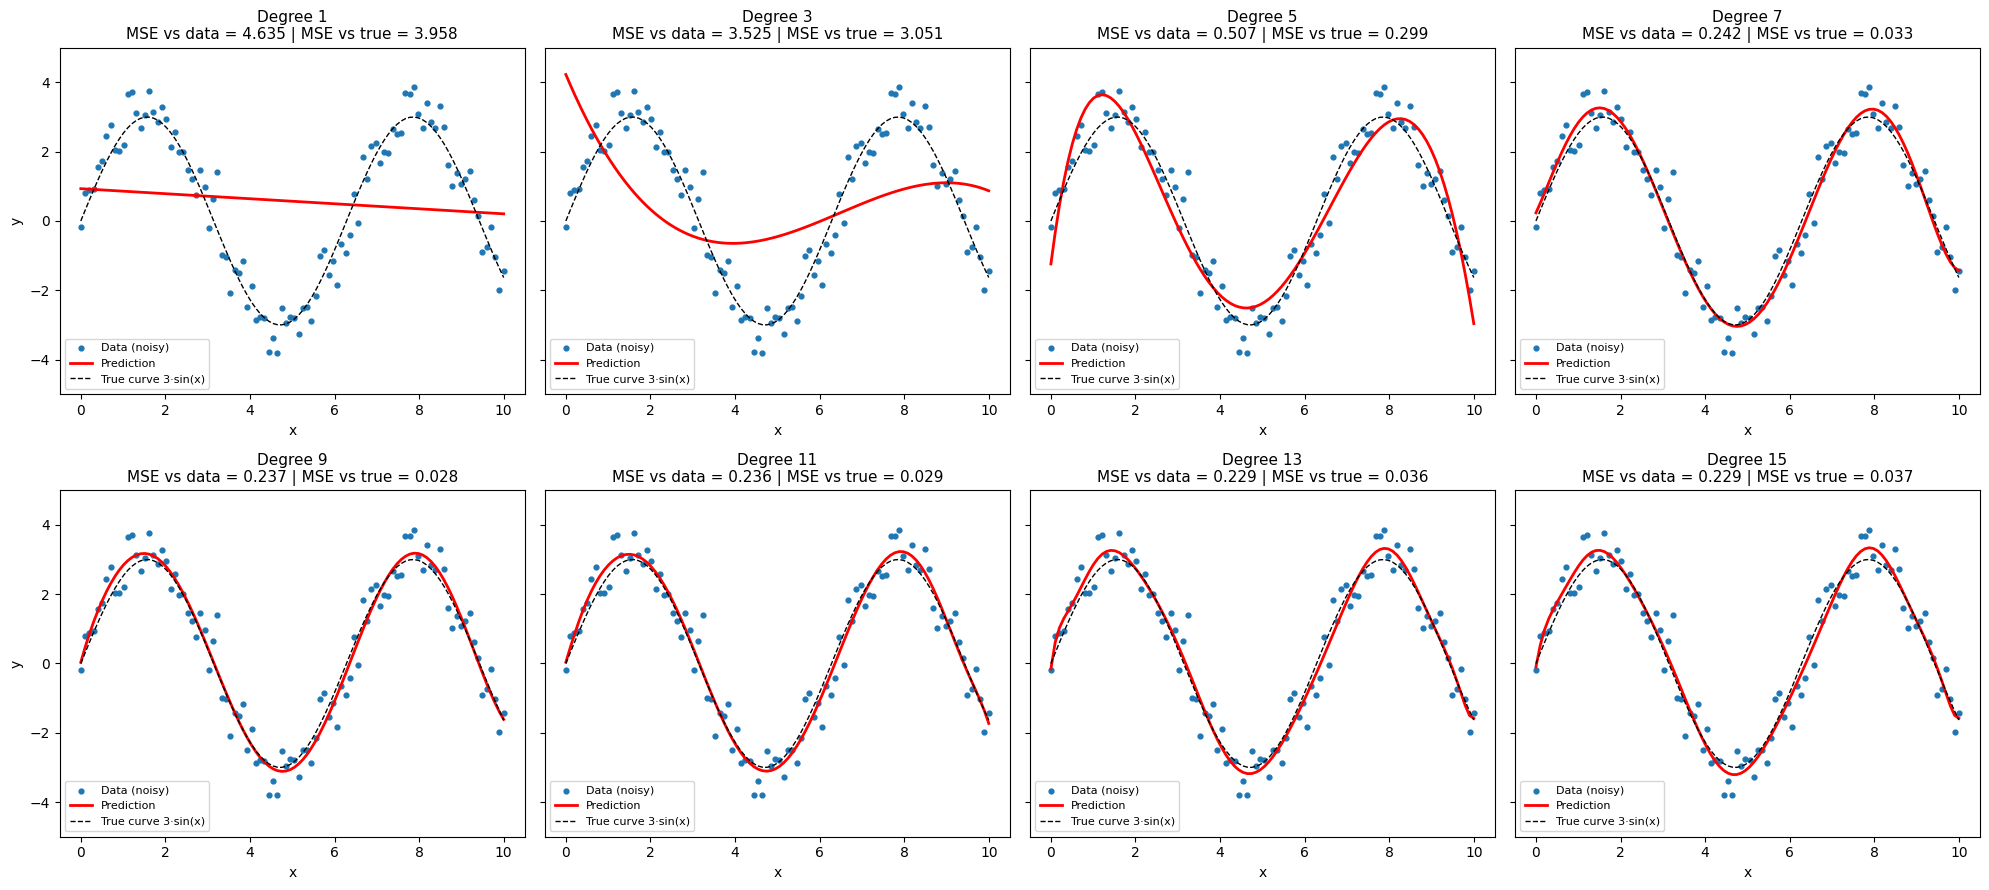

,Degree,MSE vs noisy y,MSE vs 3·sin(x),MSE vs y (raw x),MSE vs 3·sin(x) (raw x)
0,1,4.6355,3.9584,4.6355,3.9584
1,3,3.5246,3.0508,3.5246,3.0508
2,5,0.5068,0.2991,0.5068,0.2991
3,7,0.2419,0.0331,0.2419,0.0331
4,9,0.2374,0.0278,0.2374,0.0278
5,11,0.2364,0.0291,0.2364,0.0291
6,13,0.2294,0.0361,0.2470,0.0310
7,15,0.2288,0.0367,1.2919,0.9300


In [8]:
# Task 2 (continued)
degrees = [1, 3, 5, 7, 9, 11, 13, 15]
y_true = 3 * np.sin(x)
order = np.argsort(x)

# x runs from 0 to 10, so x^15 ~ 1e15: the raw design matrix is badly ill-conditioned and
# least squares loses accuracy (training MSE would wrongly *increase* with degree).
# Rescaling x to [-1, 1] before the transform spans the same polynomials but keeps the
# numbers well-conditioned.
x_scaled = (x - x.min()) / (x.max() - x.min()) * 2 - 1

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
mse_rows = []
for ax, d in zip(axes.flatten(), degrees):
    Z = poly_transform(x_scaled, d, include_bias=True)
    model = LinearRegression(fit_intercept=False).fit(Z, y)   # bias is already the column of ones
    y_pred = model.predict(Z)

    mse_noisy = mean_squared_error(y, y_pred)
    mse_true = mean_squared_error(y_true, y_pred)
    mse_rows.append([d, mse_noisy, mse_true])

    ax.scatter(x, y, s=12, color='tab:blue', label='Data (noisy)')
    ax.plot(x[order], y_pred[order], color='red', lw=2, label='Prediction')
    ax.plot(x[order], y_true[order], 'k--', lw=1, label='True curve 3·sin(x)')
    ax.set_title(f'Degree {d}\nMSE vs data = {mse_noisy:.3f} | MSE vs true = {mse_true:.3f}', fontsize=11)
    ax.set_xlabel('x')
    ax.set_ylim(-5, 5)
    ax.legend(fontsize=8, loc='lower left')
axes[0, 0].set_ylabel('y'); axes[1, 0].set_ylabel('y')
plt.tight_layout()
plt.show()

# Same fit on the *unscaled* x, to show the numerical problem
raw_rows = []
for d in degrees:
    Z_raw = poly_transform(x, d, include_bias=True)
    p_raw = LinearRegression(fit_intercept=False).fit(Z_raw, y).predict(Z_raw)
    raw_rows.append([mean_squared_error(y, p_raw), mean_squared_error(y_true, p_raw)])

table = pd.DataFrame(mse_rows, columns=['Degree', 'MSE vs noisy y', 'MSE vs 3·sin(x)'])
table[['MSE vs y (raw x)', 'MSE vs 3·sin(x) (raw x)']] = raw_rows
table.round(4)